# The hexagon FBQC code, built from `fusion_mod` on Hadamarded chains

The three-colour hexagonal fusion network, built from a Hadamard-conjugated
fusion primitive. Half the lattice vertices are *hadamarded*; every qubit of a
hadamarded vertex's cluster chain carries an extra Hadamard, and every fusion is
`fusion_mod`. Measurements are named by the Pauli they read on the **normal**
endpoint followed by the Pauli on the **hadamarded** one, giving the labels `XZ`
and `ZX` and the six step names `rXZ gZX bXZ rZX gXZ bZX`.

The notebook is self-contained: geometry, the primitive, the resource state, the
checks and the logicals are all built and verified here, against the circuit
itself (`has_flow`, `detector_error_model`) rather than trusted from the
derivation.

| § | what happens |
|---|---|
| 1 | Geometry: the three-colour lattice and the hadamarded sublattice |
| 2 | `fusion_mod`: the primitive, and the `XZ` / `ZX` labels |
| 3 | The resource state: cluster chains and the Hadamard layer |
| 4 | The circuit: the six-step schedule, spelled out gate by gate |
| 5 | Checks: the six weight-12 checks, written out and verified |
| 6 | Logicals: the six closed forms, and the nullspace check |

In [1]:
import numpy as np
import stim
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from collections import Counter, defaultdict
from itertools import combinations

print("stim", stim.__version__)

stim 1.16.0


---
## 1. Geometry

Points live on a triangular lattice in axial coordinates `(i, j)`. A
**hexagon** centred at `c` is the six points `c + dir` for `dir` in `HEX_DIRS`,
and one **tile** groups a red, a green and a blue hexagon by centre offset:

| colour | centre offset |
|---|---|
| red   | (0, -1) |
| green | (1, 0)  |
| blue  | (-1, 1) |

Tiles repeat rigidly on a square grid with translation vectors `(3, 0)` and
`(0, 3)`; with `x_max, y_max` tiles the lattice is periodic with period
`(3*x_max, 3*y_max)`. Every edge borders exactly two hexagons of two different
colours, and the edge is coloured by the **missing third** colour -- so a
hexagon's six boundary edges are never its own colour.

**The hadamarded sublattice.** For a hexagon centred at `(i, j)`, the three
vertices at offsets `(-1, 1)`, `(1, 0)` and `(0, -1)` are declared
*hadamarded*. These are the odd entries of `HEX_DIRS`, so they alternate around
each hexagon's boundary. That alternation is globally consistent: the set is
exactly the points with `(i - j) % 3 == 2`, and **every edge has exactly one
hadamarded endpoint** -- all checked below. That last property is what makes
"the normal endpoint" and "the hadamarded endpoint" of a fusion well defined,
and hence the `XZ` / `ZX` labelling of §2.

In [2]:
# The six axial nearest-neighbour directions, in cyclic (hexagon-boundary) order.
HEX_DIRS = [(1, -1), (1, 0), (0, 1), (-1, 1), (-1, 0), (0, -1)]

# Hexagon centres within one tile, relative to the tile origin (0, 0).
TILE_OFFSETS = {"red": (0, -1), "green": (1, 0), "blue": (-1, 1)}

# Vertices at these offsets from a hexagon centre are "hadamarded".
HAD_OFFSETS = [(-1, 1), (1, 0), (0, -1)]

TILE_VECS = [(3, 0), (0, 3)]  # tile-to-tile translation


class HexLattice:
    """Periodic tiling of the triangular lattice by red/green/blue hexagons.

    `x_max`, `y_max` tiles in each direction, wrapping periodically with
    period (3*x_max, 3*y_max). `hadamarded` is the vertex subset that carries
    the Hadamard-conjugated end of every fusion it takes part in.
    """

    def __init__(self, x_max, y_max):
        self.x_max, self.y_max = x_max, y_max
        self.Lx, self.Ly = 3 * x_max, 3 * y_max

        # hexagons[(colour, centre)] = the 6 vertices, in cyclic order
        self.hexagons = {}
        for a in range(x_max):
            for b in range(y_max):
                tx, ty = 3 * a, 3 * b
                for colour, (dx, dy) in TILE_OFFSETS.items():
                    c = self.wrap((tx + dx, ty + dy))
                    verts = [self.wrap((c[0] + ox, c[1] + oy)) for ox, oy in HEX_DIRS]
                    self.hexagons[(colour, c)] = verts

        self.points = sorted(set(p for verts in self.hexagons.values() for p in verts))

        # every boundary edge -> the set of hexagon colours it borders
        edge_touch = defaultdict(set)
        for (colour, c), verts in self.hexagons.items():
            for k in range(6):
                p, q = verts[k], verts[(k + 1) % 6]
                edge_touch[frozenset((p, q))].add(colour)
        self.edge_touch = edge_touch

        # each edge borders exactly 2 colours; it is coloured by the 3rd
        all_colours = set(TILE_OFFSETS)
        self.edge_colour = {edge: (all_colours - cols).pop()
                            for edge, cols in edge_touch.items()}

        # the hadamarded vertices, collected from every hexagon
        self.hadamarded = set()
        for (colour, c) in self.hexagons:
            for ox, oy in HAD_OFFSETS:
                self.hadamarded.add(self.wrap((c[0] + ox, c[1] + oy)))
        self.normal = set(self.points) - self.hadamarded

    def wrap(self, p):
        return (p[0] % self.Lx, p[1] % self.Ly)

    def colour_of_edge(self, p, q):
        """Colour of the edge between two (adjacent) points, wrapped periodically."""
        return self.edge_colour[frozenset((self.wrap(p), self.wrap(q)))]

    def is_hadamarded(self, p):
        return self.wrap(p) in self.hadamarded

    def split(self, p, q):
        """(hadamarded endpoint, normal endpoint) of an edge."""
        return (p, q) if self.is_hadamarded(p) else (q, p)

    @property
    def distance(self):
        """Code distance of the patch: 2 * max(i) / 3, i.e. 2 * x_max."""
        return 2 * self.Lx // 3


net = HexLattice(4, 4)
print(f"tiles = {net.x_max * net.y_max}, hexagons = {len(net.hexagons)}, points = {len(net.points)}")
print(f"hadamarded = {len(net.hadamarded)}, normal = {len(net.normal)}")
print(f"period = ({net.Lx}, {net.Ly}), distance = 2*{net.Lx}/3 = {net.distance}")

tiles = 16, hexagons = 48, points = 96
hadamarded = 48, normal = 48
period = (12, 12), distance = 2*12/3 = 8


### Sanity checks

The tiling has to hold up before anything downstream means anything: every edge
borders exactly two colours, the three colour pairs occur equally often, and
every point has exactly one edge of each colour. Then the three properties the
hadamarded set needs -- it must be **consistent** (no vertex declared
hadamarded by one hexagon and normal by another), it must match the closed form
`(i - j) % 3 == 2`, and **every edge must straddle the bipartition**.

In [3]:
touch_dist = Counter(len(cols) for cols in net.edge_touch.values())
print("edge colour-touch-count distribution:", dict(touch_dist))
assert touch_dist.keys() == {2}, "every edge should border exactly 2 hexagon colours"

pair_dist = Counter(frozenset(cols) for cols in net.edge_touch.values())
print("colour-pair distribution:", {tuple(sorted(k)): v for k, v in pair_dist.items()})
assert len(set(pair_dist.values())) == 1, "colour pairs should occur equally often"

point_colour_degree = defaultdict(Counter)
for edge, colour in net.edge_colour.items():
    p, r = tuple(edge)
    point_colour_degree[p][colour] += 1
    point_colour_degree[r][colour] += 1
degree_profiles = Counter(tuple(sorted(point_colour_degree[p].items())) for p in net.points)
print("point colour-degree profiles:", dict(degree_profiles))
assert set(degree_profiles) == {(("blue", 1), ("green", 1), ("red", 1))}, \
    "every point should have exactly one red, one green, one blue edge"

# --- the hadamarded sublattice ---------------------------------------------
normal_from_hexes = set()
for (colour, c) in net.hexagons:
    for ox, oy in HEX_DIRS:
        if (ox, oy) not in HAD_OFFSETS:
            normal_from_hexes.add(net.wrap((c[0] + ox, c[1] + oy)))
print("\nhadamarded n normal =", len(net.hadamarded & normal_from_hexes), "(want 0)")
assert not (net.hadamarded & normal_from_hexes)
assert net.hadamarded | normal_from_hexes == set(net.points)

print("residues (i-j)%3 of hadamarded:", set((p[0] - p[1]) % 3 for p in net.hadamarded))
print("residues (i-j)%3 of normal:    ", set((p[0] - p[1]) % 3 for p in net.normal))
assert net.hadamarded == {p for p in net.points if (p[0] - p[1]) % 3 == 2}

straddle = Counter(sum(net.is_hadamarded(p) for p in edge) for edge in net.edge_colour)
print("hadamarded endpoints per edge:", dict(straddle), "(want {1: all})")
assert straddle.keys() == {1}, "every edge must have exactly one hadamarded endpoint"
print("\nhadamarded sublattice is a clean bipartition: OK")

edge colour-touch-count distribution: {2: 144}
colour-pair distribution: {('blue', 'red'): 48, ('green', 'red'): 48, ('blue', 'green'): 48}
point colour-degree profiles: {(('blue', 1), ('green', 1), ('red', 1)): 96}

hadamarded n normal = 0 (want 0)
residues (i-j)%3 of hadamarded: {2}
residues (i-j)%3 of normal:     {0}
hadamarded endpoints per edge: {1: 144} (want {1: all})

hadamarded sublattice is a clean bipartition: OK


### Visualise

Axial `(i, j)` maps to the plane as `x = i + j/2`, `y = j*sqrt(3)/2`, so each
hexagon renders regular. Hadamarded vertices are drawn as open squares, normal
ones as filled circles -- the alternation around every hexagon boundary should
be visible by eye.

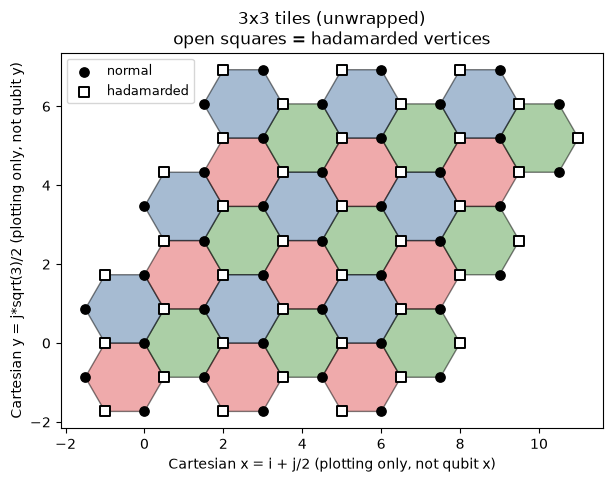

In [4]:
def to_xy(p):
    """Cartesian embedding for plotting only -- NOT the qubit (x, y) label."""
    i, j = p
    return (i + 0.5 * j, (np.sqrt(3) / 2) * j)


COLOURS = {"red": "#e15759", "green": "#59a14f", "blue": "#4e79a7"}


def mark_sublattice(ax, points, is_had, xy=to_xy, size=45):
    """Filled circle = normal, open square = hadamarded."""
    had = [xy(p) for p in points if is_had(p)]
    nor = [xy(p) for p in points if not is_had(p)]
    if nor:
        ax.scatter(*zip(*nor), color="black", s=size, zorder=3, label="normal")
    if had:
        ax.scatter(*zip(*had), facecolors="white", edgecolors="black", marker="s",
                   linewidths=1.4, s=size + 15, zorder=3, label="hadamarded")


def plot_patch(x_max, y_max, ax=None):
    """Unwrapped x_max x y_max patch of tiles, with the sublattice marked."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 7))
    pts = set()
    for a in range(x_max):
        for b in range(y_max):
            tx, ty = 3 * a, 3 * b
            for colour, (dx, dy) in TILE_OFFSETS.items():
                c = (tx + dx, ty + dy)
                verts = [to_xy((c[0] + ox, c[1] + oy)) for ox, oy in HEX_DIRS]
                ax.add_patch(Polygon(verts, closed=True, facecolor=COLOURS[colour],
                                     edgecolor="black", linewidth=1, alpha=0.5))
                for ox, oy in HEX_DIRS:
                    pts.add((c[0] + ox, c[1] + oy))
    mark_sublattice(ax, sorted(pts), lambda p: (p[0] - p[1]) % 3 == 2)
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.legend(loc="upper left", fontsize=9)
    ax.set_xlabel("Cartesian x = i + j/2 (plotting only, not qubit x)")
    ax.set_ylabel("Cartesian y = j*sqrt(3)/2 (plotting only, not qubit y)")
    ax.set_title(f"{x_max}x{y_max} tiles (unwrapped)\n"
                 "open squares = hadamarded vertices")
    return ax


plot_patch(3, 3)
plt.show()

### Raw-coordinate plot

Each point at its own `(x, y)` axial coordinate -- a literal picture of what
`Spacetime.q(x, y, t)` addresses. Edges that wrap across the periodic boundary
are marked with a diamond at each endpoint rather than a line across the plot.
Every coloured edge should join one filled circle to one open square.

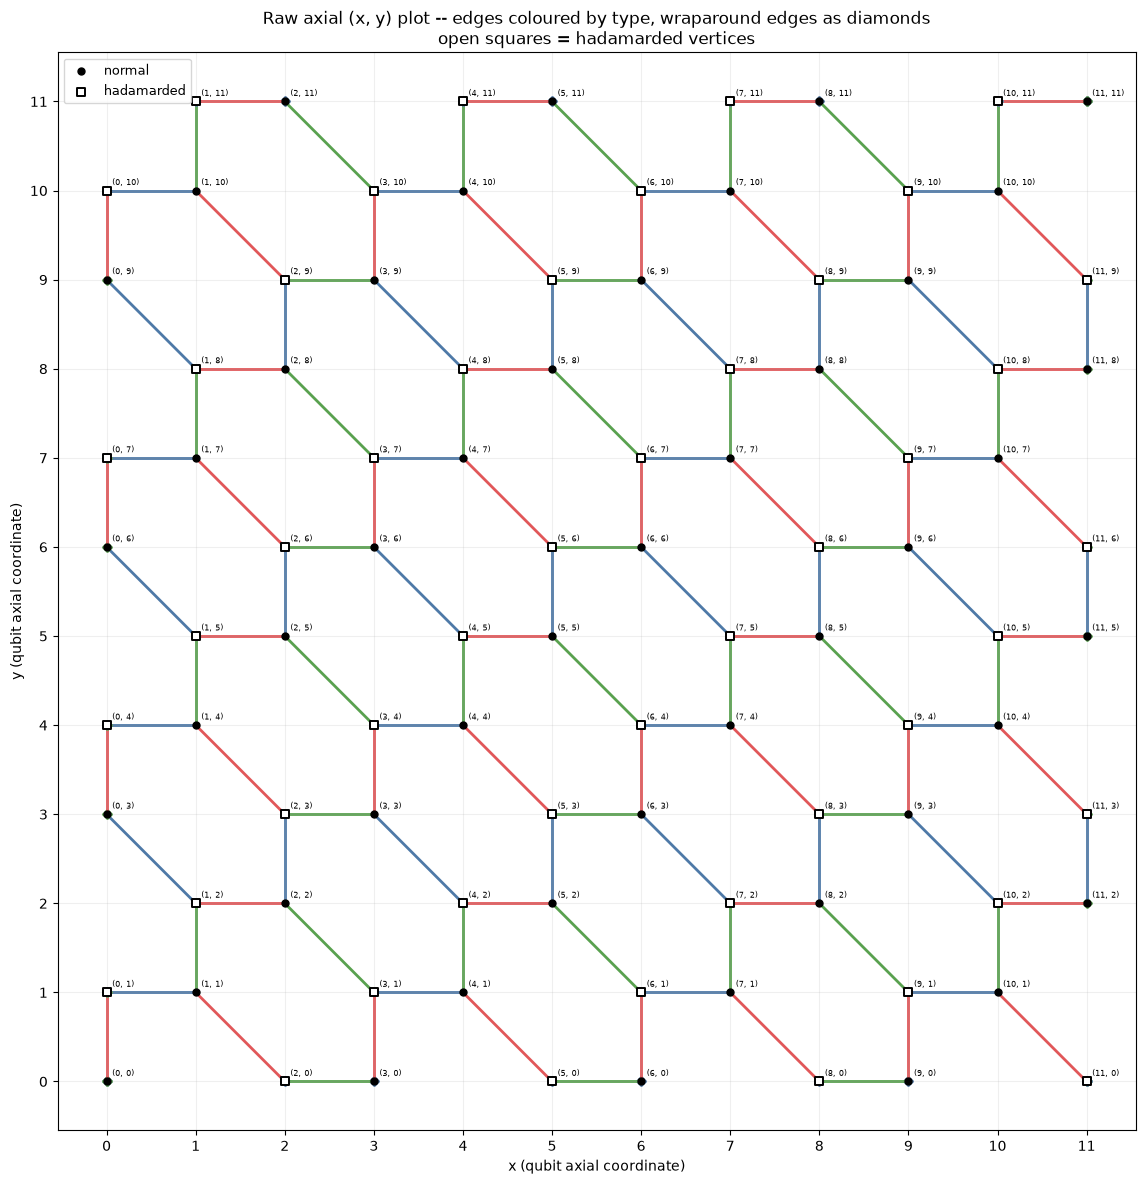

In [5]:
def plot_raw(net, ax=None, figsize=(14, 14)):
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    for edge, colour in net.edge_colour.items():
        p, r = tuple(edge)
        di, dj = r[0] - p[0], r[1] - p[1]
        if (di, dj) in HEX_DIRS or (-di, -dj) in HEX_DIRS:
            ax.plot([p[0], r[0]], [p[1], r[1]], color=COLOURS[colour], linewidth=2, zorder=1)
        else:
            ax.plot(*p, marker="D", color=COLOURS[colour], markersize=5, zorder=1)
            ax.plot(*r, marker="D", color=COLOURS[colour], markersize=5, zorder=1)

    mark_sublattice(ax, net.points, net.is_hadamarded, xy=lambda p: p, size=25)
    for p in net.points:
        ax.annotate(f"{p}", p, fontsize=6, xytext=(4, 4), textcoords="offset points", zorder=4)

    ax.set_xlabel("x (qubit axial coordinate)")
    ax.set_ylabel("y (qubit axial coordinate)")
    ax.set_xticks(range(net.Lx))
    ax.set_yticks(range(net.Ly))
    ax.grid(alpha=0.2)
    ax.set_aspect("equal")
    ax.legend(loc="upper left", fontsize=9)
    ax.set_title("Raw axial (x, y) plot -- edges coloured by type, wraparound edges "
                 "as diamonds\nopen squares = hadamarded vertices")
    return ax


plot_raw(net)
plt.show()

---
## 2. `fusion_mod`: the fusion primitive

Every edge has exactly one hadamarded endpoint (§1), so a fusion always has a
well-defined **normal** qubit and **hadamarded** qubit. `fusion_mod` puts a
Hadamard on the hadamarded one:

```
H had ; CNOT nor had ; H nor ; M nor ; M had
```

against the standard destructive fusion `CNOT a b ; H a ; M a ; M b`. The two
records are then

| record | reads on the normal endpoint | reads on the hadamarded endpoint | label |
|---|---|---|---|
| `rec[-2]`, the normal qubit's outcome | X | Z | `XZ` |
| `rec[-1]`, the hadamarded qubit's outcome | Z | X | `ZX` |

A two-character Pauli string is written in that order throughout -- normal
first, hadamarded second -- which is also stim's qubit order below, since qubit
0 is taken to be the normal endpoint.

Because the primitive names its two qubits by sublattice rather than by an
abstract `a`/`b`, **there is no role rule**: the normal endpoint is always the
CNOT control, the hadamarded one always the target, and the record labels never
depend on the step.

In [6]:
def fusion_mod(circuit, q_nor, q_had, p_meas=0.0):
    """The destructive fusion used throughout: a Hadamard on the hadamarded
    endpoint, then a standard fusion with the normal endpoint as control.

        H had ; CNOT nor had ; H nor ; M nor ; M had

    Appends two records, in this order:

        rec[-2] = X_nor Z_had   ("XZ")
        rec[-1] = Z_nor X_had   ("ZX")

    `p_meas` flips each outcome independently with that probability."""
    circuit.append("H", [q_had])
    circuit.append("CNOT", [q_nor, q_had])
    circuit.append("H", [q_nor])
    if p_meas > 0:
        circuit.append("M", [q_nor, q_had], p_meas)
    else:
        circuit.append("M", [q_nor, q_had])


def fusion_std(circuit, a, b, p_meas=0.0):
    """The standard destructive fusion, shown here only for contrast:
    rec[-2] = X_a X_b, rec[-1] = Z_a Z_b."""
    circuit.append("CNOT", [a, b])
    circuit.append("H", [a])
    if p_meas > 0:
        circuit.append("M", [a, b], p_meas)
    else:
        circuit.append("M", [a, b])


def reads(build_fn, pre_h=()):
    """{record -> the Pauli string it reads}, from stim's flow checker.
    Qubit 0 is the normal endpoint, qubit 1 the hadamarded one, so the string
    reads (normal, hadamarded). `pre_h` lists qubits already carrying an extra
    Hadamard -- used in §3."""
    c = stim.Circuit()
    for q in pre_h:
        c.append("H", [q])
    build_fn(c, 0, 1)
    out = {}
    for ps in ("XX", "XZ", "ZX", "ZZ"):
        for rec in ("rec[-2]", "rec[-1]"):
            if c.has_flow(stim.Flow(f"{ps} -> {rec}")):
                out[rec] = ps
    return out


print("Pauli strings read as (normal, hadamarded):\n")
for name, fn in (("fusion_std", fusion_std), ("fusion_mod", fusion_mod)):
    m = reads(fn)
    print(f"  {name:11s} rec[-2] = {m['rec[-2]']}   rec[-1] = {m['rec[-1]']}")
m = reads(fusion_mod)
assert (m["rec[-2]"], m["rec[-1]"]) == ("XZ", "ZX")
print("\nfusion_mod labels its records XZ (normal's outcome) and ZX (hadamarded's): OK")

Pauli strings read as (normal, hadamarded):

  fusion_std  rec[-2] = XX   rec[-1] = ZZ
  fusion_mod  rec[-2] = XZ   rec[-1] = ZX

fusion_mod labels its records XZ (normal's outcome) and ZX (hadamarded's): OK


---
## 3. The resource state: cluster chains and the Hadamard layer

Every lattice point gets `total_t = 6 * n_cycles` qubits, one per timestep,
addressed by `Spacetime.q(x, y, t)`. The state is prepared in three layers:

1. **`R` then `H`** -- every qubit in `|+>`.
2. **`CZ`** between the *same* vertex at adjacent timesteps. There are **no
   spatial CZs**: spatial connectivity comes entirely from the fusions. The
   resource state is a disjoint union of 1D cluster **chains**, one per lattice
   point, of length `total_t`, each **closed in time** -- the `t = total_t - 1`
   qubit is bonded back to `t = 0` -- and stabilised by `X_t Z_{t-1} Z_{t+1}`
   with the index arithmetic mod `total_t`. §6 uses this.
3. **The Hadamard layer** -- an extra `H` on **every qubit of every hadamarded
   chain**, applied after the CZs. Normal chains are left alone.

### What the records then read

An extra `H` in front of a destructive measurement conjugates what that
measurement reads. On a hadamarded chain's qubit that `H` sits immediately
before `fusion_mod`'s own `H had`, with nothing in between, so the two cancel:

```
H had ; H had ; CNOT nor had ; H nor ; M   =   CNOT nor had ; H nor ; M
```

Each fusion therefore reads a *symmetric* pair, and the slot named `XZ` carries
the `XX` outcome while `ZX` carries `ZZ` -- confirmed from stim below rather
than asserted. Two consequences worth being explicit about:

- The `XZ`/`ZX` names describe the record **slots** (which qubit's outcome), not
  what they read once the Hadamard layer is in place. Every rule below is stated
  in slot terms, so it stays valid either way.
- With the conjugation cancelled on every edge, this network **is** the
  unmodified hexagon code, reached by putting the Hadamard in the resource state
  instead of in the fusion. That is why the check and logical structure of
  `Hexagon_fbqc_walkthrough.ipynb` carries over intact, with `XZ` wherever that
  notebook writes `XX` and `ZX` wherever it writes `ZZ`.

In [7]:
# the Hadamard layer's H, then fusion_mod's own H on the same (hadamarded) qubit
m = reads(fusion_mod, pre_h=(1,))
print("with the Hadamard layer in place, one fusion reads:")
for rec, slot in (("rec[-2]", "XZ"), ("rec[-1]", "ZX")):
    print(f"   slot {slot} ({rec}) physically reads {m[rec]}")
assert (m["rec[-2]"], m["rec[-1]"]) == ("XX", "ZZ")
print("\nso: slot XZ <-> the XX outcome,  slot ZX <-> the ZZ outcome")
print("(the same pair the standard fusion gives:",
      dict(reads(fusion_std)) == {"rec[-2]": "XX", "rec[-1]": "ZZ"}, ")")

with the Hadamard layer in place, one fusion reads:
   slot XZ (rec[-2]) physically reads XX
   slot ZX (rec[-1]) physically reads ZZ

so: slot XZ <-> the XX outcome,  slot ZX <-> the ZZ outcome
(the same pair the standard fusion gives: True )


---
## 4. The circuit

The six-step schedule fuses one edge colour per timestep, alternating the two
record kinds. `t // 6` is the cycle and `t % 6` indexes the schedule:

| t % 6 | name | edge colour | native kind |
|---|---|---|---|
| 0 | `rXZ` | red   | `XZ` |
| 1 | `gZX` | green | `ZX` |
| 2 | `bXZ` | blue  | `XZ` |
| 3 | `rZX` | red   | `ZX` |
| 4 | `gXZ` | green | `XZ` |
| 5 | `bZX` | blue  | `ZX` |

The name's second half is the step's **native kind** -- the slot the checks of
§5 treat as "this step's own", the other being the *opposite* kind. Note that
`rec[-2]` is the `XZ` slot and `rec[-1]` the `ZX` slot at *every* step,
regardless of the native kind: that positional fixedness is what having no role
rule buys, and it is asserted in the sanity check below.

At step `t` every edge of that colour is fused at once, which is a perfect
matching of the lattice points, so each qubit `(point, t)` is consumed by
exactly one fusion -- checked below. `t` wraps mod `total_t`, and that wrap is
what closes each chain.

In [8]:
class Spacetime:
    """`net`'s points, each replicated over `total_t = 6 * n_cycles` timesteps
    that wrap periodically (timestep `total_t` is timestep `0`).

    `n_cycles` defaults to the patch distance `net.distance`. §5 runs at 2
    cycles; §6 needs the full period `n_cycles = x_max` because two of the
    logicals march across the whole lattice before closing."""

    def __init__(self, net, n_cycles=None):
        if n_cycles is None:
            n_cycles = net.distance
        self.net = net
        self.n_cycles = n_cycles
        self.total_t = 6 * n_cycles
        self.point_id = {p: i for i, p in enumerate(net.points)}
        self.n_qubits = len(net.points) * self.total_t

    def q(self, x, y, t):
        return self.point_id[(x, y)] * self.total_t + (t % self.total_t)


# (edge colour, native record kind) for each of the 6 steps of one cycle
STEP_SCHEDULE = [("red", "XZ"), ("green", "ZX"), ("blue", "XZ"),
                 ("red", "ZX"), ("green", "XZ"), ("blue", "ZX")]
STEP_NAMES = [c[0] + k for c, k in STEP_SCHEDULE]   # rXZ gZX bXZ rZX gXZ bZX
OPPOSITE = {"XZ": "ZX", "ZX": "XZ"}


def build(st, p_meas=0.0):
    """Prepare |+> everywhere, CZ each vertex to its own next (periodic)
    timestep, Hadamard every qubit of every hadamarded chain, then run the
    6-step schedule with `fusion_mod`.

    Returns (circuit, records, nmeas) with
    records[(t, colour, kind, p, r)] = (XZ record, ZX record)."""
    net = st.net
    circuit = stim.Circuit()
    circuit.append("R", range(st.n_qubits))
    circuit.append("H", range(st.n_qubits))

    # layer 2: one closed 1D cluster chain per lattice point, along the time axis
    for p in net.points:
        for t in range(st.total_t):
            circuit.append("CZ", [st.q(*p, t), st.q(*p, t + 1)])

    # layer 3: an extra H on every qubit of every hadamarded chain
    circuit.append("H", sorted(st.q(*p, t) for p in net.points
                               if net.is_hadamarded(p) for t in range(st.total_t)))

    colour_edges = defaultdict(list)
    for edge, colour in net.edge_colour.items():
        colour_edges[colour].append(tuple(edge))

    records, n = {}, 0
    for c in range(st.n_cycles):
        for step, (colour, kind) in enumerate(STEP_SCHEDULE):
            t = 6 * c + step
            for (p, r) in colour_edges[colour]:
                had, nor = net.split(p, r)
                fusion_mod(circuit, st.q(*nor, t), st.q(*had, t), p_meas)
                records[(t, colour, kind, p, r)] = (n, n + 1)   # (XZ, ZX)
                n += 2

    return circuit, records, n


def find_record(records, t, colour, kind, p, r):
    """(XZ record, ZX record); does not care which way round the edge is given."""
    return records.get((t, colour, kind, p, r)) or records[(t, colour, kind, r, p)]


net = HexLattice(4, 4)
st = Spacetime(net, n_cycles=2)
circ, records, nmeas = build(st)
print(f"points = {len(net.points)}, total_t = {st.total_t}, qubits = {st.n_qubits}")
print(f"fusions = {nmeas // 2}, measurement records = {nmeas}")

points = 96, total_t = 12, qubits = 1152
fusions = 576, measurement records = 1152


### Sanity check: every qubit consumed exactly once

Each of `st.n_qubits` qubits must be consumed by exactly one fusion. Also
printed: one sample edge per step, confirming the normal/hadamarded split and
that the record slots are positionally fixed.

In [9]:
used = Counter()
for (t, colour, kind, p, r) in records:
    used[st.q(*p, t)] += 1
    used[st.q(*r, t)] += 1
print("distribution of 'times consumed':", dict(Counter(used.values())))
bad = [i for i in range(st.n_qubits) if used[i] != 1]
print("qubits not consumed exactly once:", len(bad) if bad else "none")
assert not bad

per_t = Counter(t for (t, *_rest) in records)
print("fusions per timestep, distribution of counts:", dict(Counter(per_t.values())))
print("expected per timestep:", len(net.points) // 2)

print("\none sample edge per step:")
for step, (colour, kind) in enumerate(STEP_SCHEDULE):
    (t, _c, _k, p, r) = next(k for k in records if k[0] == step and k[1] == colour)
    had, nor = net.split(p, r)
    r_xz, r_zx = find_record(records, t, colour, kind, p, r)
    assert r_zx == r_xz + 1, "XZ is always rec[-2] and ZX always rec[-1]"
    print(f"  t = {step}  {STEP_NAMES[step]}:  normal = {nor}, hadamarded = {had}"
          f"   native kind = {kind}")

distribution of 'times consumed': {1: 1152}
qubits not consumed exactly once: none
fusions per timestep, distribution of counts: {48: 12}
expected per timestep: 48

one sample edge per step:
  t = 0  rXZ:  normal = (1, 1), hadamarded = (2, 0)   native kind = XZ
  t = 1  gZX:  normal = (1, 10), hadamarded = (1, 11)   native kind = ZX
  t = 2  bXZ:  normal = (0, 0), hadamarded = (1, 11)   native kind = XZ
  t = 3  rZX:  normal = (1, 1), hadamarded = (2, 0)   native kind = ZX
  t = 4  gXZ:  normal = (1, 10), hadamarded = (1, 11)   native kind = XZ
  t = 5  bZX:  normal = (0, 0), hadamarded = (1, 11)   native kind = ZX


---
## 5. Checks

A hexagon's six boundary edges are never its own colour (§1), so they split 3
and 3 between the other two colours. A check takes a 6-step window, drops the
two steps of the hexagon's own colour, and uses the remaining **4 steps x 3
same-coloured boundary edges = weight 12**. Each hexagon carries two -- an `X`
check and a `Z` check, the same window shifted by 3 steps -- so there are **6
check types**, and `2 x (number of hexagons)` independent checks per cycle.

Which record each term pulls follows one rule: **a `Z` check takes the step's
native kind, an `X` check the opposite.** Written out, the six are:

| check | | | | |
|---|---|---|---|---|
| **blue X** | t=0 `rXZ` red `ZX` | t=1 `gZX` green `XZ` | t=3 `rZX` red `XZ` | t=4 `gXZ` green `ZX` |
| **blue Z** | t=3 `rZX` red `ZX` | t=4 `gXZ` green `XZ` | t=6 `rXZ` red `XZ` | t=7 `gZX` green `ZX` |
| **red X** | t=4 `gXZ` green `ZX` | t=5 `bZX` blue `XZ` | t=7 `gZX` green `XZ` | t=8 `bXZ` blue `ZX` |
| **red Z** | t=1 `gZX` green `ZX` | t=2 `bXZ` blue `XZ` | t=4 `gXZ` green `XZ` | t=5 `bZX` blue `ZX` |
| **green X** | t=2 `bXZ` blue `ZX` | t=3 `rZX` red `XZ` | t=5 `bZX` blue `XZ` | t=6 `rXZ` red `ZX` |
| **green Z** | t=5 `bZX` blue `ZX` | t=6 `rXZ` red `XZ` | t=8 `bXZ` blue `XZ` | t=9 `rZX` red `ZX` |

`t` is relative to the start of the cycle, so `t >= 6` reaches into the next
one; cycle `c` uses `(6*c + t) % total_t`.

Every one has the same shape: **`ZX, XZ, XZ, ZX`** -- the opposite slot at the
two ends of the window, the native one in the middle. §6's chain condition
`z_t = x_{t-1} + x_{t+1}` is what forces it: each end's `z` is generated by its
single neighbouring `x`, and the two middle conditions cancel in pairs. Taking
the *same* slot at all four steps -- the natural first guess -- leaves `z = 0`
on every chain while `x` is nonzero, and fails at the very first condition.

In [10]:
# GF(2) toolkit, used here and in §6.

def rref(A):
    """Row-reduced echelon form over GF(2); returns (rows, pivot columns)."""
    R = A.copy() % 2
    rows, cols = R.shape
    piv, r = [], 0
    for c in range(cols):
        idx = np.flatnonzero(R[r:, c])
        if idx.size == 0:
            continue
        p = r + idx[0]
        R[[r, p]] = R[[p, r]]
        m = R[:, c].astype(bool).copy(); m[r] = False
        R[m] ^= R[r]
        piv.append(c); r += 1
        if r == rows:
            break
    return R[:r], piv


def nullspace(A):
    """Basis of {v : A v = 0} over GF(2), as rows."""
    A = np.asarray(A, dtype=np.uint8) % 2
    R, piv = rref(A)
    pivset = set(piv)
    free = [c for c in range(A.shape[1]) if c not in pivset]
    B = np.zeros((len(free), A.shape[1]), dtype=np.uint8)
    for t, f in enumerate(free):
        B[t, f] = 1
        for ri, p in enumerate(piv):
            if R[ri, f]:
                B[t, p] = 1
    return B


def rank(M):
    M = np.asarray(M, dtype=np.uint8)
    return rref(M)[0].shape[0] if len(M) else 0


def deterministic_parities(circuit, nmeas, extra=400):
    """Outcome subsets whose parity is constant across all noiseless shots --
    every parity that could serve as a check or a logical, found by brute force
    rather than by construction."""
    S = circuit.compile_sampler().sample(shots=nmeas + extra).astype(np.uint8)
    aug = np.concatenate([S % 2, np.ones((len(S), 1), dtype=np.uint8)], axis=1)
    return nullspace(aug)[:, :nmeas]      # drop the constant column

In [11]:
# (timestep relative to the cycle start, edge colour, record slot to pull).
CHECK_SPEC = {
    ("blue",  "X"): [(0, "red",   "ZX"), (1, "green", "XZ"), (3, "red",   "XZ"), (4, "green", "ZX")],
    ("blue",  "Z"): [(3, "red",   "ZX"), (4, "green", "XZ"), (6, "red",   "XZ"), (7, "green", "ZX")],
    ("red",   "X"): [(4, "green", "ZX"), (5, "blue",  "XZ"), (7, "green", "XZ"), (8, "blue",  "ZX")],
    ("red",   "Z"): [(1, "green", "ZX"), (2, "blue",  "XZ"), (4, "green", "XZ"), (5, "blue",  "ZX")],
    ("green", "X"): [(2, "blue",  "ZX"), (3, "red",   "XZ"), (5, "blue",  "XZ"), (6, "red",   "ZX")],
    ("green", "Z"): [(5, "blue",  "ZX"), (6, "red",   "XZ"), (8, "blue",  "XZ"), (9, "red",   "ZX")],
}

# the spec must agree with the schedule and with the native/opposite rule
for (hex_colour, xz), terms in CHECK_SPEC.items():
    assert len(terms) == 4
    for (dt, edge_colour, pull) in terms:
        colour, native = STEP_SCHEDULE[dt % 6]
        assert colour == edge_colour, \
            f"{hex_colour} {xz}: t={dt} is a {colour} step, spec says {edge_colour}"
        want = native if xz == "Z" else OPPOSITE[native]
        assert pull == want, f"{hex_colour} {xz}: t={dt} should pull {want}, spec says {pull}"
        assert edge_colour != hex_colour, "a hexagon never borders its own colour"
    assert [p for (_d, _c, p) in terms] == ["ZX", "XZ", "XZ", "ZX"]
print("CHECK_SPEC agrees with the step schedule and the native/opposite rule: OK")
print("every check has the shape ZX, XZ, XZ, ZX")


def hexagon_boundary_by_colour(net, colour, centre):
    """The 6 boundary edges of hexagon (colour, centre), grouped by edge colour
    (3 of each of the 2 non-native colours)."""
    verts = net.hexagons[(colour, centre)]
    by_colour = defaultdict(list)
    for k in range(6):
        p, r = verts[k], verts[(k + 1) % 6]
        by_colour[net.colour_of_edge(p, r)].append((p, r))
    return by_colour


def check_rows(st, records, nmeas, spec=CHECK_SPEC):
    """One GF(2) row per (hexagon, X/Z, cycle), straight from the spec."""
    net = st.net
    rows, meta = [], []
    for (hex_colour, centre) in net.hexagons:
        by_colour = hexagon_boundary_by_colour(net, hex_colour, centre)
        for xz in ("X", "Z"):
            for c in range(st.n_cycles):
                v = np.zeros(nmeas, dtype=np.uint8)
                for (dt, edge_colour, pull) in spec[(hex_colour, xz)]:
                    t = (6 * c + dt) % st.total_t
                    colour, native = STEP_SCHEDULE[t % 6]
                    for (p, r) in by_colour[colour]:
                        r_xz, r_zx = find_record(records, t, colour, native, p, r)
                        v[r_xz if pull == "XZ" else r_zx] ^= 1
                rows.append(v)
                meta.append((hex_colour, centre, xz, c))
    return np.array(rows, dtype=np.uint8), meta


checks, check_meta = check_rows(st, records, nmeas)
print(f"\nhexagons = {len(net.hexagons)}, cycles = {st.n_cycles} -> "
      f"{len(checks)} checks (expect {len(net.hexagons) * 2 * st.n_cycles})")
print("weight distribution:", dict(Counter(checks.sum(axis=1).tolist())))
print(f"independent: rank = {rank(checks)}")

CHECK_SPEC agrees with the step schedule and the native/opposite rule: OK
every check has the shape ZX, XZ, XZ, ZX

hexagons = 48, cycles = 2 -> 192 checks (expect 192)
weight distribution: {12: 192}
independent: rank = 190


### Verification

`detector_error_model()` refuses to build if any detector is not deterministic
in the noiseless circuit, so one call validates all of them at once. Then each
check is confirmed individually with `has_flow`, broken down by hexagon colour
and check type, and cross-checked against the brute-force deterministic-parity
space.

In [12]:
def add_detectors(circuit, rows, nmeas):
    tgt = lambda i: stim.target_rec(int(i) - nmeas)
    for row in rows:
        circuit.append("DETECTOR", [tgt(i) for i in np.flatnonzero(row)])


probe = circ.copy()
add_detectors(probe, checks, nmeas)
try:
    probe.detector_error_model(decompose_errors=True)
    print(f"DEM built: all {probe.num_detectors} detectors deterministic")
except Exception as e:
    print("DEM FAILED:", str(e).split("\n")[0])

ok = Counter()
for row, (hc, _centre, xz, _c) in zip(checks, check_meta):
    f = stim.Flow("1 -> " + " xor ".join(f"rec[{int(j) - nmeas}]" for j in np.flatnonzero(row)))
    ok[(hc, xz, circ.has_flow(f))] += 1
print("\nper-check has_flow:")
for hc in ("red", "green", "blue"):
    line = "   "
    for xz in ("X", "Z"):
        good, bad = ok[(hc, xz, True)], ok[(hc, xz, False)]
        line += f"{hc:>5s} {xz}: {good:3d} valid / {good + bad:3d}    "
    print(line)
assert all(not ok[(hc, xz, False)] for hc in ("red", "green", "blue") for xz in ("X", "Z"))

V = deterministic_parities(circ, nmeas)
print(f"\nbrute-force deterministic-parity space: dim {rank(V)}")
print(f"checks lie inside it: {rank(np.concatenate([V, checks])) == rank(V)}")

DEM built: all 192 detectors deterministic



per-check has_flow:
     red X:  32 valid /  32      red Z:  32 valid /  32    
   green X:  32 valid /  32    green Z:  32 valid /  32    
    blue X:  32 valid /  32     blue Z:  32 valid /  32    



brute-force deterministic-parity space: dim 196
checks lie inside it: True


---
## 6. Logicals

The six closed-form logicals of `Hexagon_fbqc_walkthrough.ipynb` §5 carry over
structurally, with the slot dictionary of §3:

| that notebook | here |
|---|---|
| the `XX` record | the **`XZ`** slot |
| the `ZZ` record | the **`ZX`** slot |

**The mapping is the same for X and Z logicals** -- it is a property of the
fusion, not of the logical. The cell after the constructions checks this by
building all six with the slots exchanged and watching four of them fail.

Two of the six (Vertical Z, Horizontal Z) **march** a single column/row across
the whole lattice, one position every 2 timesteps, so they only close after
sweeping every column/row exactly once. That needs the full period
`n_cycles = x_max` (`= Lx/3`), not the 2-cycle circuit of §4-5, so this section
rebuilds its own circuit at that size on the same `net`. The full write-up of
the derivations, including the false starts, is in
`vertical_horizontal_logicals_notes.txt`.

In [13]:
st6 = Spacetime(net, n_cycles=net.x_max)
circ6, records6, nmeas6 = build(st6)
print(f"st6: n_cycles={st6.n_cycles}, total_t={st6.total_t}, "
      f"n_qubits={st6.n_qubits}, nmeas={nmeas6}")

st6: n_cycles=4, total_t=24, n_qubits=2304, nmeas=2304


### Column/row native colour

Every point's edges split by *axis*: an **internal** edge joins two points with
the same `x` (or the same `y`); a **crossing** edge joins column/row `k` to
`k+1`. Both are a function of `k % 3` only, colour-wise -- but internal and
crossing are offset from each other, and independently so for x vs. y. Rather
than assume this, derive both tables directly from `net.edge_colour` by
classifying every edge by its offset along the axis, and assert each residue
gives one consistent colour.

In [14]:
def internal_crossing_tables(net, axis):
    """Colour of the same-`axis`-coordinate ('internal') edge and the
    axis-coordinate k->k+1 ('crossing') edge, as a function of k%3."""
    length = net.Lx if axis == 0 else net.Ly
    internal, crossing = defaultdict(set), defaultdict(set)
    for edge, colour in net.edge_colour.items():
        p, r = tuple(edge)
        d = (r[axis] - p[axis]) % length
        if d == 0:
            internal[p[axis] % 3].add(colour)
        elif d == 1:
            crossing[p[axis] % 3].add(colour)
        elif d == length - 1:
            crossing[r[axis] % 3].add(colour)
        else:
            raise ValueError("edge spans more than one lattice step", edge, d)
    assert all(len(v) == 1 for v in internal.values()), internal
    assert all(len(v) == 1 for v in crossing.values()), crossing
    return {k: v.pop() for k, v in internal.items()}, {k: v.pop() for k, v in crossing.items()}


_pce_cache = {}

def point_colour_edge(net, p, colour):
    """The unique edge of `colour` touching point p (every point has exactly
    one -- checked in §1). Indexed once per lattice: §7 calls this inside the
    marching loop, where a linear scan over every edge would dominate."""
    key = id(net)
    if key not in _pce_cache:
        table = {}
        for edge, c in net.edge_colour.items():
            a, b = tuple(edge)
            table[(a, c)] = (a, b)
            table[(b, c)] = (a, b)
        _pce_cache[key] = table
    return _pce_cache[key][(p, colour)]


NATIVE_OF_X, CROSSING_OF_X = internal_crossing_tables(net, axis=0)
NATIVE_OF_Y, CROSSING_OF_Y = internal_crossing_tables(net, axis=1)
print("x: internal", NATIVE_OF_X, " crossing(k,k+1)", CROSSING_OF_X)
print("y: internal", NATIVE_OF_Y, " crossing(k,k+1)", CROSSING_OF_Y)

# red's own internal residue fixes the stationary logicals' column pair
P0X = next(k for k, c in NATIVE_OF_X.items() if c == "red")
P0Y = next(k for k, c in NATIVE_OF_Y.items() if c == "red")
print(f"red's own internal residue: x -> p0 = {P0X}, y -> p0 = {P0Y}")

x: internal {1: 'green', 2: 'blue', 0: 'red'}  crossing(k,k+1) {0: 'blue', 2: 'green', 1: 'red'}
y: internal {0: 'green', 1: 'blue', 2: 'red'}  crossing(k,k+1) {1: 'green', 2: 'blue', 0: 'red'}
red's own internal residue: x -> p0 = 0, y -> p0 = 2


### The three closed forms

- **Timelike X / Timelike Z** live at a fixed cycle -- no spatial sweep -- and
  use every edge of all three colours at three consecutive timesteps, spanning
  either the first half of a cycle (steps 1,2,3) or the second (steps 4,5,6).
- **Vertical Z / Horizontal Z** sweep a single column (or row) across the whole
  lattice, one position every 2 timesteps. At each step every point in that
  column contributes its edge of the round's colour; if that colour is the
  column's own internal colour the edge is shared by two points in the
  enumeration and must be de-duplicated, while a crossing edge needs no de-dup.
- **Vertical X / Horizontal X** do *not* march: they sit on two adjacent columns
  (or rows) for all points along the other axis, repeating identically every
  cycle, with the schedule's colour order mapped onto three fixed spatial roles.

`slot()` is the one place the §3 dictionary is applied, so the `swap` flag below
can exchange the two records everywhere at once.

In [15]:
def slot(record_pair, kind, swap=False):
    """Pick the XZ or the ZX record of one fusion. `swap=True` exchanges them
    everywhere -- used only to test the mapping in the next cell."""
    r_xz, r_zx = record_pair
    if swap:
        r_xz, r_zx = r_zx, r_xz
    return r_xz if kind == "XZ" else r_zx


def timelike_row(net, st, records, nmeas, c0, steps, mode, swap=False):
    """`mode='native'` pulls each step's own kind; `mode='anti'` the opposite --
    the same native/opposite rule the §5 checks use."""
    v = np.zeros(nmeas, dtype=np.uint8)
    for step in steps:
        colour, native = STEP_SCHEDULE[step - 1]
        t = (6 * c0 + (step - 1)) % st.total_t
        kind = native if mode == "native" else OPPOSITE[native]
        for edge, c in net.edge_colour.items():
            if c != colour:
                continue
            p, r = tuple(edge)
            v[slot(find_record(records, t, colour, native, p, r), kind, swap)] ^= 1
    return v


def marching_row(net, st, records, nmeas, axis, start, t0,
                 kind_own, kind_ext, native_map, swap=False, direction=-1):
    v = np.zeros(nmeas, dtype=np.uint8)
    length = net.Lx if axis == 0 else net.Ly
    for k in range(st.total_t):
        t = (t0 + k) % st.total_t
        colour, native = STEP_SCHEDULE[t % 6]
        pos = (start + direction * (k // 2)) % length
        is_own = (colour == native_map[pos % 3])
        seen = set()
        for p in net.points:
            if p[axis] != pos:
                continue
            edge = point_colour_edge(net, p, colour)
            if is_own:
                key = frozenset(edge)
                if key in seen:
                    continue
                seen.add(key)
            kind = kind_own if is_own else kind_ext
            v[slot(find_record(records, t, colour, native, *edge), kind, swap)] ^= 1
    return v


def build_stationary(net, st, records, nmeas, axis, p0, p1, swap=False):
    v = np.zeros(nmeas, dtype=np.uint8)
    pattern = [({p0}, "ZX"), ({p1}, "XZ"), ({p0, p1}, "ZX"),
               ({p0}, "XZ"), ({p1}, "ZX"), ({p0, p1}, "XZ")]
    for c in range(st.n_cycles):
        for step, (ps, kind) in enumerate(pattern):
            t = 6 * c + step
            colour, native = STEP_SCHEDULE[step]
            for edge, col in net.edge_colour.items():
                if col != colour:
                    continue
                p, r = tuple(edge)
                if {p[axis], r[axis]} != ps:
                    continue
                v[slot(find_record(records, t, colour, native, p, r), kind, swap)] ^= 1
    return v


def closed_form_logicals(net, st, records, nmeas, swap=False):
    """All six closed forms for any lattice size. The internal-colour tables
    and red's own residue are re-derived per lattice rather than reused from
    the globals above, so §7 can call this at Lx = 12, 18, 24."""
    nx, _ = internal_crossing_tables(net, axis=0)
    ny, _ = internal_crossing_tables(net, axis=1)
    p0x = next(k for k, c in nx.items() if c == "red")
    p0y = next(k for k, c in ny.items() if c == "red")
    return {
        "Timelike X":   timelike_row(net, st, records, nmeas, 0, [1, 2, 3], "anti", swap),
        "Timelike Z":   timelike_row(net, st, records, nmeas, 1, [4, 5, 6], "native", swap),
        "Vertical Z":   marching_row(net, st, records, nmeas, 0, 3, 0, "XZ", "ZX", nx, swap),
        "Horizontal Z": marching_row(net, st, records, nmeas, 1, 2, 0, "XZ", "ZX", ny, swap),
        "Vertical X":   build_stationary(net, st, records, nmeas, 0, p0x, p0x + 1, swap),
        "Horizontal X": build_stationary(net, st, records, nmeas, 1, p0y, p0y + 1, swap),
    }


logicals = closed_form_logicals(net, st6, records6, nmeas6)
for name, v in logicals.items():
    print(f"{name:14s} weight {int(v.sum()):4d}")

Timelike X     weight  144
Timelike Z     weight  144
Vertical Z     weight  144
Horizontal Z   weight  144
Vertical X     weight  128
Horizontal X   weight  128


### Is the slot mapping really the same for X and Z?

Worth testing rather than assuming, since the natural guess is that X-type
logicals should read the slots the other way round. Build all six again with
`swap=True` -- every `XZ` becomes `ZX` and vice versa -- and check determinism.

In [16]:
swapped = closed_form_logicals(net, st6, records6, nmeas6, swap=True)
print(f"{'logical':14s} {'uniform XZ<->XX':>16s} {'swapped':>10s}")
for name in logicals:
    row = []
    for L in (logicals, swapped):
        v = L[name]
        f = stim.Flow("1 -> " + " xor ".join(f"rec[{int(j) - nmeas6}]" for j in np.flatnonzero(v)))
        row.append(circ6.has_flow(f))
    print(f"{name:14s} {str(row[0]):>16s} {str(row[1]):>10s}")

assert all(circ6.has_flow(stim.Flow("1 -> " + " xor ".join(
    f"rec[{int(j) - nmeas6}]" for j in np.flatnonzero(v)))) for v in logicals.values())
print("\nall six work with the uniform mapping XX -> XZ, ZZ -> ZX.")
print("Swapping breaks the Timelike pair and both marching logicals; the two")
print("stationary ones survive but are a different operator, not the same")
print("logical shifted by a check -- so the uniform mapping is the right one.")

logical         uniform XZ<->XX    swapped


Timelike X                 True      False


Timelike Z                 True      False


Vertical Z                 True      False


Horizontal Z               True      False


Vertical X                 True       True


Horizontal X               True       True



all six work with the uniform mapping XX -> XZ, ZZ -> ZX.
Swapping breaks the Timelike pair and both marching logicals; the two
stationary ones survive but are a different operator, not the same
logical shifted by a check -- so the uniform mapping is the right one.


### Nullspace check

Two things, mirroring the original notebook. (1) The six are independent of the
checks and of each other: adding them to the check basis raises the rank by
exactly 6, no more and no less. (2) Together they **span** the whole
deterministic-parity space -- `rank(checks) + 6` equals the dimension found by
brute-force sampling, so nothing deterministic is left unaccounted for.

In [17]:
checks6, _meta6 = check_rows(st6, records6, nmeas6)
r_checks = rank(checks6)
r_combined = rank(np.concatenate([checks6] + [v[None, :] for v in logicals.values()]))
print(f"rank(checks)                = {r_checks}")
print(f"rank(checks + 6 logicals)   = {r_combined}   (want +6: {r_combined == r_checks + 6})")
assert r_combined == r_checks + 6

V6 = deterministic_parities(circ6, nmeas6)
dim_V = rank(V6)
print(f"\nbrute-force deterministic-parity space: dim {dim_V}")
print(f"checks {r_checks} + logicals 6 = {r_checks + 6}  ->  spans it: {r_checks + 6 == dim_V}")
print(f"every logical lies inside it: "
      f"{rank(np.concatenate([V6] + [v[None, :] for v in logicals.values()])) == dim_V}")
assert r_checks + 6 == dim_V
print("\ncheck space + 6 logicals = the entire deterministic space: OK")

rank(checks)                = 382
rank(checks + 6 logicals)   = 388   (want +6: True)



brute-force deterministic-parity space: dim 388
checks 382 + logicals 6 = 388  ->  spans it: True
every logical lies inside it: True

check space + 6 logicals = the entire deterministic space: OK


---
### Where this leaves it

- The hadamarded set is a clean bipartition and every edge has exactly one
  hadamarded endpoint, so `fusion_mod` and the `XZ`/`ZX` labels are well defined
  with no role rule anywhere (§1-§2).
- The resource state is one closed cluster chain per lattice point, plus a
  Hadamard on every qubit of every hadamarded chain. That Hadamard cancels the
  one inside `fusion_mod`, so each record reads a symmetric pair and the slot
  `XZ` carries `XX`, `ZX` carries `ZZ` (§3).
- The six weight-12 checks all have the shape `ZX, XZ, XZ, ZX` and every one of
  them is deterministic; the DEM builds (§5).
- The six closed-form logicals carry over with the single uniform slot mapping,
  verified against the swapped alternative, and checks + logicals exactly span
  the deterministic space (§6).

---
## 7. Preliminary threshold check

Three noise models, swept at `Lx = 12, 18, 24` (`x_max = 4, 6, 8`, run at full
closure `n_cycles = x_max` so the marching logicals close), 15 probability
points each, decoded with `pymatching` against `detector_error_model()`. A
logical error is counted when **any** of the six observables is mispredicted.

| case | noise | where |
|---|---|---|
| 1 | each fusion outcome flipped independently with probability `p` | on the `M` instructions |
| 2 | `DEPOLARIZE1(r)` on every qubit | right after the chains are prepared |
| 3 | `Z_ERROR(r)` on every qubit | right after the chains are prepared |

**"After preparing the chains" means after the CZ layer and *before* the
Hadamard layer** (§3). That placement matters for case 3 and not for case 2: a
depolarizing channel is invariant under Clifford conjugation, but a `Z` error on
a hadamarded chain is carried through the Hadamard layer and arrives at the
fusion as an `X`.

**Preliminary** is meant literally: 10,000 shots per point and a
crossing-interpolation estimate, with no finite-size-scaling fit and no error
bars. Enough to locate each threshold to a fraction of a percent and to see the
curves order correctly by distance; not enough to quote a number to three
digits.

### How the sweeps avoid rebuilding

The structure -- checks, logicals, detector/observable instructions -- does not
depend on the noise rate, so it is built once per lattice size and cached
(`~12 s` at `Lx = 24`). After that the two cases behave differently:

- **Cases 2 and 3** splice the noise between the two halves of the circuit:
  `prep + noise(r) + rest`. Stim concatenation is cheap, so each new `r` costs a
  DEM build and a sample, not a rebuild.
- **Case 1** does not even need that. A noisy `M` reports the wrong outcome but
  leaves the post-measurement state alone, and every qubit is consumed exactly
  once, so the flip cannot propagate: sampling the *noiseless* circuit once and
  flipping bits afterwards is distributionally exact. The matching graph is also
  `p`-independent (every edge carries the same weight, and MWPM is invariant
  under a uniform rescaling), so one matcher built at a reference `p` serves the
  whole curve.

One consequence of reusing a single raw sample across a case-1 curve: points
along that curve are correlated rather than independent. Each individual point
is still an unbiased binomial estimate.

In [18]:
import pymatching
import time

P_REF = 0.01          # reference rate for the p-independent case-1 matcher


def build_split(st, p_meas=0.0):
    """`build` in three pieces, so noise can be spliced at either boundary:

        init | cz | rest

    `init` creates every qubit in |+> (R then H), `cz` is the chain-bonding
    layer, `rest` is the Hadamard layer plus every fusion. Cases 2 and 3 splice
    between `cz` and `rest`; case 4 splices between `init` and `cz`."""
    net = st.net
    init = stim.Circuit()
    init.append("R", range(st.n_qubits))
    init.append("H", range(st.n_qubits))

    cz = stim.Circuit()
    for p in net.points:
        for t in range(st.total_t):
            cz.append("CZ", [st.q(*p, t), st.q(*p, t + 1)])

    rest = stim.Circuit()
    rest.append("H", sorted(st.q(*p, t) for p in net.points
                            if net.is_hadamarded(p) for t in range(st.total_t)))
    colour_edges = defaultdict(list)
    for edge, colour in net.edge_colour.items():
        colour_edges[colour].append(tuple(edge))
    records, n = {}, 0
    for c in range(st.n_cycles):
        for step, (colour, kind) in enumerate(STEP_SCHEDULE):
            t = 6 * c + step
            for (p, r) in colour_edges[colour]:
                had, nor = net.split(p, r)
                fusion_mod(rest, st.q(*nor, t), st.q(*had, t), p_meas)
                records[(t, colour, kind, p, r)] = (n, n + 1)
                n += 2
    return init, cz, rest, records, n


_structure_cache = {}


def structure(x_max):
    """Everything that does not depend on the noise rate, built once per size."""
    if x_max in _structure_cache:
        return _structure_cache[x_max]
    t0 = time.time()
    net_ = HexLattice(x_max, x_max)
    st_ = Spacetime(net_, n_cycles=x_max)
    init_, cz_, rest_, rec_, nm_ = build_split(st_)
    _, _, rest_meas, _, _ = build_split(st_, P_REF)      # case-1 reference matcher
    ch_, _ = check_rows(st_, rec_, nm_)
    lg_ = np.array(list(closed_form_logicals(net_, st_, rec_, nm_).values()), dtype=np.uint8)
    obs_ = stim.Circuit()
    tgt = lambda i: stim.target_rec(int(i) - nm_)
    for v in ch_:
        obs_.append("DETECTOR", [tgt(i) for i in np.flatnonzero(v)])
    for k, v in enumerate(lg_):
        obs_.append("OBSERVABLE_INCLUDE", [tgt(i) for i in np.flatnonzero(v)], k)
    _structure_cache[x_max] = (st_, init_, cz_, rest_, rest_meas, obs_, ch_, lg_, nm_)
    print(f"  [Lx={3*x_max}: {nm_} outcomes, {obs_.num_detectors} detectors, "
          f"rank(checks)={rank(ch_)}, {time.time() - t0:.1f}s]", flush=True)
    return _structure_cache[x_max]


def rows_to_parities_packed(outcomes, rows, _cache={}):
    """Parities of `rows` over each shot, XOR-ing 8 shots at a time by packing
    the shots axis into bits. Each row's column indices are cached."""
    packed = np.packbits(outcomes, axis=0)
    key = id(rows)
    if key not in _cache:
        _cache[key] = [np.flatnonzero(rows[r]) for r in range(rows.shape[0])]
    out = np.zeros((packed.shape[0], rows.shape[0]), dtype=np.uint8)
    for r, idx in enumerate(_cache[key]):
        out[:, r] = np.bitwise_xor.reduce(packed[:, idx], axis=1)
    return np.unpackbits(out, axis=0, count=outcomes.shape[0])


def sweep_measurement(x_max, ps, shots=10000, seed=1234):
    """Case 1. One noiseless sample, one matcher, readout flips per p."""
    st_, init_, cz_, rest_, rest_meas, obs_, ch_, lg_, nm_ = structure(x_max)
    prep_ = init_ + cz_
    matcher = pymatching.Matching.from_detector_error_model(
        (prep_ + rest_meas + obs_).detector_error_model(decompose_errors=True))
    raw = (prep_ + rest_).compile_sampler(
        seed=seed, skip_reference_sample=True).sample(shots).astype(np.uint8)
    rng = np.random.default_rng(seed)
    rates = []
    for p in ps:
        outcomes = raw ^ (rng.random(raw.shape) < p).astype(np.uint8)
        dets = rows_to_parities_packed(outcomes, ch_)
        obs = rows_to_parities_packed(outcomes, lg_)
        rates.append(np.any(matcher.decode_batch(dets) != obs, axis=1).sum() / shots)
    return rates


def sweep_state_noise(x_max, instruction, rs, shots=10000, seed=1234,
                      where="after_cz", decoder_instructions=None):
    """Splice `instruction(r)` on every qubit, either after the CZ layer
    (`where="after_cz"`) or on the freshly created |+> qubits before it
    (`where="at_prep"`).

    `decoder_instructions` builds the matching graph from a *different* channel
    at the same rate, leaving the sampled circuit alone. Case 5 needs it: a
    pure-Y model is not graphlike, so it is decoded on the X+Z graph."""
    st_, init_, cz_, rest_, rest_meas, obs_, ch_, lg_, nm_ = structure(x_max)
    prep_ = init_ + cz_
    def spliced(instrs, r):
        noise = stim.Circuit()
        for ins in instrs:
            noise.append(ins, range(st_.n_qubits), r)
        return (init_ + noise + cz_ + rest_ + obs_) if where == "at_prep" \
            else (init_ + cz_ + noise + rest_ + obs_)

    rates = []
    for r in rs:
        c = spliced([instruction], r)
        c_dec = c if decoder_instructions is None else spliced(decoder_instructions, r)
        matcher = pymatching.Matching.from_detector_error_model(
            c_dec.detector_error_model(decompose_errors=True))
        dets, obs = c.compile_detector_sampler(seed=seed).sample(
            shots, separate_observables=True)
        rates.append(np.any(matcher.decode_batch(dets) != obs, axis=1).sum() / shots)
    return rates


def find_crossing(ps, r1, r2):
    """Interpolated crossing between two curves, skipping exact ties (both
    curves rounding to the same value at low p) rather than reporting them."""
    diff = np.array(r1, dtype=float) - np.array(r2, dtype=float)
    last = None
    for i in range(len(diff)):
        if diff[i] == 0:
            continue
        if last is not None and diff[last] * diff[i] < 0:
            frac = diff[last] / (diff[last] - diff[i])
            return ps[last] + frac * (ps[i] - ps[last])
        last = i
    return None


def report(name, ps, cols, Ls, unit="p"):
    print(f"\n{name}\n{unit:>8} " + " ".join(f"{'Lx='+str(L):>9}" for L in Ls))
    for j, p in enumerate(ps):
        print(f"{p:>8.4f} " + " ".join(f"{cols[L][j]:>9.4f}" for L in Ls))
    print("\n  pairwise crossings:")
    for i in range(len(Ls) - 1):
        xc = find_crossing(ps, cols[Ls[i]], cols[Ls[i + 1]])
        print(f"    Lx={Ls[i]} x Lx={Ls[i+1]}: "
              + (f"{unit}_th ~= {xc:.4f}  ({xc*100:.2f}%)" if xc is not None
                 else "no crossing in range"))
    return [find_crossing(ps, cols[Ls[i]], cols[Ls[i + 1]]) for i in range(len(Ls) - 1)]


def plot_sweep(ps, cols, Ls, xlabel, title, crossing=None):
    plt.figure(figsize=(6, 4))
    for L in Ls:
        plt.plot(ps, cols[L], "o-", ms=4, label=f"Lx = {L}")
    if crossing:
        plt.axvline(crossing, ls="--", c="grey", lw=1,
                    label=f"crossing ~ {crossing*100:.2f}%")
    plt.xlabel(xlabel)
    plt.ylabel("logical error rate")
    plt.title(title)
    plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()


LS = [12, 18, 24]
X_MAXES = [L // 3 for L in LS]
SHOTS = 10000
print("building structure for each size (cached across all three cases):")
for xm in X_MAXES:
    structure(xm)

building structure for each size (cached across all three cases):


  [Lx=12: 2304 outcomes, 384 detectors, rank(checks)=382, 8.0s]


  [Lx=18: 7776 outcomes, 1296 detectors, rank(checks)=1294, 27.4s]


  [Lx=24: 18432 outcomes, 3072 detectors, rank(checks)=3070, 67.0s]


### Case 1 -- measurement error on every fusion outcome

`M(p)` flips each of the two outcomes of every fusion independently. 15 points
across `0.006 - 0.014`, bracketing the crossing.

  [Lx=12: 15 points in 5.6s]


  [Lx=18: 15 points in 27.3s]


  [Lx=24: 15 points in 86.1s]



Case 1: measurement error
  p_meas     Lx=12     Lx=18     Lx=24
  0.0060    0.0502    0.0177    0.0062
  0.0066    0.0707    0.0341    0.0138
  0.0071    0.0932    0.0472    0.0243
  0.0077    0.1247    0.0817    0.0471
  0.0083    0.1559    0.1118    0.0761
  0.0089    0.1910    0.1587    0.1249
  0.0094    0.2357    0.2185    0.1844
  0.0100    0.2674    0.2746    0.2657
  0.0106    0.3276    0.3530    0.3698
  0.0111    0.3728    0.4301    0.4776
  0.0117    0.4247    0.5077    0.5864
  0.0123    0.4833    0.5763    0.6784
  0.0129    0.5212    0.6440    0.7597
  0.0134    0.5588    0.7113    0.8256
  0.0140    0.6168    0.7635    0.8755

  pairwise crossings:
    Lx=12 x Lx=18: p_meas_th ~= 0.0098  (0.98%)
    Lx=18 x Lx=24: p_meas_th ~= 0.0102  (1.02%)

total 119.0s


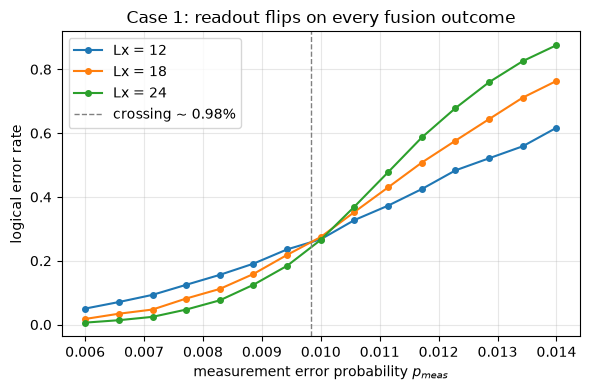

In [19]:
ps1 = np.linspace(0.006, 0.014, 15)
t0 = time.time()
cols1 = {}
for L, xm in zip(LS, X_MAXES):
    tl = time.time()
    cols1[L] = sweep_measurement(xm, ps1, shots=SHOTS)
    print(f"  [Lx={L}: {len(ps1)} points in {time.time() - tl:.1f}s]", flush=True)
xc1 = report("Case 1: measurement error", ps1, cols1, LS, unit="p_meas")
print(f"\ntotal {time.time() - t0:.1f}s")
plot_sweep(ps1, cols1, LS, "measurement error probability $p_{meas}$",
           "Case 1: readout flips on every fusion outcome",
           crossing=next((x for x in xc1 if x), None))

### Case 2 -- depolarizing noise on the prepared chains

`DEPOLARIZE1(r)` on every qubit, immediately after the CZ layer. Each qubit
picks up `X`, `Y` or `Z` with probability `r/3` each, and the error then
propagates through the Hadamard layer and the fusion gates. 15 points across
`0.004 - 0.010`.

  [Lx=12: 15 points in 7.4s]


  [Lx=18: 15 points in 29.0s]


  [Lx=24: 15 points in 73.6s]



Case 2: depolarizing on the prepared chains
       r     Lx=12     Lx=18     Lx=24
  0.0040    0.0266    0.0089    0.0025
  0.0044    0.0459    0.0170    0.0066
  0.0049    0.0631    0.0283    0.0115
  0.0053    0.0873    0.0419    0.0235
  0.0057    0.1087    0.0645    0.0427
  0.0061    0.1403    0.0975    0.0717
  0.0066    0.1784    0.1453    0.1178
  0.0070    0.2130    0.1935    0.1696
  0.0074    0.2574    0.2500    0.2451
  0.0079    0.2994    0.3208    0.3404
  0.0083    0.3433    0.3923    0.4347
  0.0087    0.3939    0.4689    0.5348
  0.0091    0.4339    0.5352    0.6345
  0.0096    0.4766    0.6072    0.7185
  0.0100    0.5279    0.6754    0.7910

  pairwise crossings:
    Lx=12 x Lx=18: r_th ~= 0.0075  (0.75%)
    Lx=18 x Lx=24: r_th ~= 0.0075  (0.75%)

total 110.0s


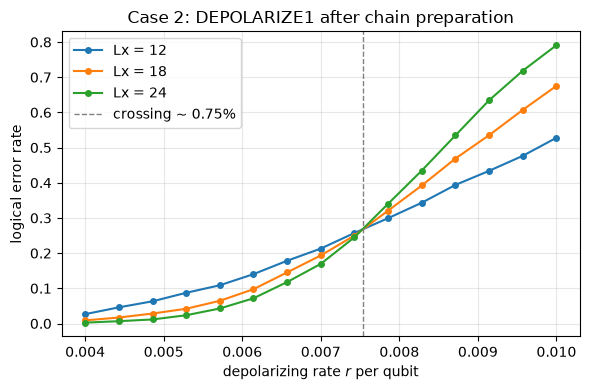

In [20]:
ps2 = np.linspace(0.004, 0.010, 15)
t0 = time.time()
cols2 = {}
for L, xm in zip(LS, X_MAXES):
    tl = time.time()
    cols2[L] = sweep_state_noise(xm, "DEPOLARIZE1", ps2, shots=SHOTS)
    print(f"  [Lx={L}: {len(ps2)} points in {time.time() - tl:.1f}s]", flush=True)
xc2 = report("Case 2: depolarizing on the prepared chains", ps2, cols2, LS, unit="r")
print(f"\ntotal {time.time() - t0:.1f}s")
plot_sweep(ps2, cols2, LS, "depolarizing rate $r$ per qubit",
           "Case 2: DEPOLARIZE1 after chain preparation",
           crossing=next((x for x in xc2 if x), None))

### Case 3 -- pure `Z` noise on the prepared chains

`Z_ERROR(r)` on every qubit, same placement. This one is worth reading
alongside its error model: a `Z` on a **normal** chain arrives at the fusion as
a `Z`, while a `Z` on a **hadamarded** chain is turned into an `X` by the
Hadamard layer -- and both end up flipping the *same* record, the `XZ` slot of
that fusion. So the two endpoints of a fusion are degenerate error mechanisms,
and the DEM has half as many of them as there are qubits. The cell below checks
that rather than asserting it. 15 points across `0.010 - 0.020`.

**Injecting the same `Z` channel at state preparation instead gives an
identical code.** `CZ` is diagonal, so it commutes with `Z` on either of its
qubits: an error placed on the freshly created `|+>` qubits passes through the
whole chain-bonding layer untouched and reaches the fusion as the same `Z`. The
two detector error models are byte-identical, so it is the same experiment, not
a fourth case -- `sweep_state_noise(x_max, "Z_ERROR", rs, where="at_prep")`
runs that placement if you want to see it land on the same threshold.

One trap if you do try it: `init` is `R` then `H`, so the qubits pass through
`|0>` on the way to `|+>`. A `Z` on `|0>` is a global phase, so noise spliced
*between* the `R` and the `H` is invisible -- the DEM has no error mechanisms
at all, and every rate at every distance returns a logical error rate of zero.
The live placement is on the `|+>` states, after `init` and before `cz`.

In [21]:
# what the Z channel actually does, at the smallest size
st_, init_, cz_, rest_, rest_meas, obs_, ch_, lg_, nm_ = structure(X_MAXES[0])
prep_ = init_ + cz_
noise = stim.Circuit(); noise.append("Z_ERROR", range(st_.n_qubits), 0.01)
dem = (prep_ + noise + rest_ + obs_).detector_error_model(decompose_errors=True)
deg, silent = Counter(), 0
for inst in dem.flattened():
    if inst.type != "error":
        continue
    d = [t for t in inst.targets_copy() if t.is_relative_detector_id()]
    o = [t for t in inst.targets_copy() if t.is_logical_observable_id()]
    deg[len(d)] += 1
    silent += (len(d) == 0 and bool(o))
print(f"Lx={3*X_MAXES[0]}: {st_.n_qubits} qubits, {nm_//2} fusions")
print(f"  distinct error mechanisms by detector count: {dict(sorted(deg.items()))}")
print(f"  mechanisms = {sum(deg.values())} = one per fusion: {sum(deg.values()) == nm_//2}")
print(f"  undetectable errors that flip a logical: {silent}")
assert silent == 0

Lx=12: 2304 qubits, 1152 fusions
  distinct error mechanisms by detector count: {2: 1152}
  mechanisms = 1152 = one per fusion: True
  undetectable errors that flip a logical: 0


  [Lx=12: 15 points in 8.0s]


  [Lx=18: 15 points in 30.1s]


  [Lx=24: 15 points in 80.4s]



Case 3: Z errors on the prepared chains
       r     Lx=12     Lx=18     Lx=24
  0.0100    0.0706    0.0249    0.0105
  0.0107    0.0894    0.0438    0.0187
  0.0114    0.1236    0.0685    0.0324
  0.0121    0.1539    0.0990    0.0615
  0.0129    0.1840    0.1368    0.1046
  0.0136    0.2289    0.1903    0.1552
  0.0143    0.2739    0.2542    0.2319
  0.0150    0.3170    0.3227    0.3256
  0.0157    0.3752    0.3952    0.4283
  0.0164    0.4169    0.4783    0.5360
  0.0171    0.4831    0.5525    0.6344
  0.0179    0.5224    0.6217    0.7258
  0.0186    0.5695    0.7027    0.8028
  0.0193    0.6197    0.7531    0.8626
  0.0200    0.6628    0.8048    0.9065

  pairwise crossings:
    Lx=12 x Lx=18: r_th ~= 0.0148  (1.48%)
    Lx=18 x Lx=24: r_th ~= 0.0149  (1.49%)

total 118.4s


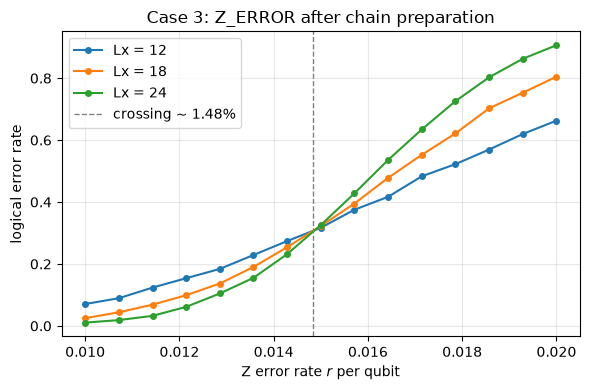

In [22]:
ps3 = np.linspace(0.010, 0.020, 15)
t0 = time.time()
cols3 = {}
for L, xm in zip(LS, X_MAXES):
    tl = time.time()
    cols3[L] = sweep_state_noise(xm, "Z_ERROR", ps3, shots=SHOTS)
    print(f"  [Lx={L}: {len(ps3)} points in {time.time() - tl:.1f}s]", flush=True)
xc3 = report("Case 3: Z errors on the prepared chains", ps3, cols3, LS, unit="r")
print(f"\ntotal {time.time() - t0:.1f}s")
plot_sweep(ps3, cols3, LS, "Z error rate $r$ per qubit",
           "Case 3: Z_ERROR after chain preparation",
           crossing=next((x for x in xc3 if x), None))

### Cases 4 and 5 -- `X` and `Y` noise on the prepared chains

The same splice point as cases 2 and 3: on the chains, after the CZ layer.

**Why not at state preparation.** Applying these at `init` instead -- on the
freshly created `|+>` qubits -- is degenerate for every single-qubit Pauli, so
there is nothing to sweep there:

| channel on `\|+>` | what happens |
|---|---|
| `X` | `X\|+> = \|+>`. The DEM has **zero** error mechanisms; every rate at every distance gives a logical error rate of 0. |
| `Y` | `Y\|+> ~ \|->`, so it acts as `Z` does. Its DEM is **byte-identical** to the `Z`-at-prep model, which is itself identical to case 3. |
| `Z` | `Z\|+> = \|->`, and `CZ` is diagonal so it commutes through the whole bonding layer: identical to case 3 (noted above). |

After the CZ layer the qubits are entangled and none of this applies -- `X` no
longer commutes with `CZ`, so it spreads onto the chain neighbours, and the
three Paulis become three genuinely different channels. The cell below confirms
all of it against stim.

**A warning about case 4.** Unlike cases 1-3, its two pairwise crossings do not
agree: `Lx = 18` and `Lx = 24` sit almost on top of each other across the whole
range and cross far below where `Lx = 12` crosses `Lx = 18`. Whatever sets the
effective distance against this channel is barely growing between those two
sizes, so the case-4 number is **not a converged threshold** -- it is two
different crossings, quoted as such. The window below is widened to 0.008-0.022
so both are visible rather than one falling off the edge.

**One decoder caveat, for case 5.** A `Y` is an `X` and a `Z` on the same qubit,
so each `Y` error flips the union of their symptoms: every mechanism in the
pure-`Y` model has **four** detectors and stim cannot decompose it into
graphlike pieces. `pymatching` accepts the model but then fails at decode time
(*"No perfect matching could be found"*). Case 5 therefore decodes on the graph
built from an `X`+`Z` channel at the same rate -- the standard "split `Y` into
`X·Z`" decomposition. That decoder is mismatched on purpose: it treats the two
halves of each `Y` as independent, so the case-5 number is a *decoder-limited*
threshold, not the best achievable one.

In [23]:
st_, init_, cz_, rest_, rest_meas, obs_, ch_, lg_, nm_ = structure(X_MAXES[0])

def dem_at(instrs, where, r=0.013, **kw):
    noise = stim.Circuit()
    for ins in instrs:
        noise.append(ins, range(st_.n_qubits), r)
    c = (init_ + noise + cz_ + rest_ + obs_) if where == "at_prep" \
        else (init_ + cz_ + noise + rest_ + obs_)
    return c.detector_error_model(decompose_errors=True, **kw)

def flat(d):
    return sorted(str(i) for i in d.flattened())

def n_err(d):
    return sum(1 for i in d.flattened() if i.type == "error")

print("at state preparation, on the |+> states:")
print(f"   X: {n_err(dem_at(['X_ERROR'], 'at_prep')):5d} error mechanisms  <- invisible")
print(f"   Y DEM identical to the Z-at-prep DEM: "
      f"{flat(dem_at(['Y_ERROR'], 'at_prep')) == flat(dem_at(['Z_ERROR'], 'at_prep'))}")
print(f"   Z-at-prep DEM identical to the Z-after-CZ DEM (case 3): "
      f"{flat(dem_at(['Z_ERROR'], 'at_prep')) == flat(dem_at(['Z_ERROR'], 'after_cz'))}")
assert n_err(dem_at(["X_ERROR"], "at_prep")) == 0

print("\nafter the CZ layer, on the prepared chains:")
xa, za = dem_at(["X_ERROR"], "after_cz"), dem_at(["Z_ERROR"], "after_cz")
print(f"   X: {n_err(xa):5d} mechanisms, identical to Z: {flat(xa) == flat(za)}")
ya = dem_at(["Y_ERROR"], "after_cz", ignore_decomposition_failures=True)
deg = Counter(len([t for t in i.targets_copy() if t.is_relative_detector_id()])
              for i in ya.flattened() if i.type == "error")
print(f"   Y: {n_err(ya):5d} mechanisms, detector-degree {dict(sorted(deg.items()))} "
      f"-> not graphlike")
try:
    dem_at(["Y_ERROR"], "after_cz")
    print("   Y decomposes")
except Exception as e:
    print(f"   Y refuses to decompose: {str(e).splitlines()[0][:60]}")
ref = pymatching.Matching.from_detector_error_model(dem_at(["X_ERROR", "Z_ERROR"], "after_cz"))
print(f"   X+Z reference graph: {ref.num_edges} edges -- the case-5 decoder")

at state preparation, on the |+> states:
   X:     0 error mechanisms  <- invisible
   Y DEM identical to the Z-at-prep DEM: True
   Z-at-prep DEM identical to the Z-after-CZ DEM (case 3): True

after the CZ layer, on the prepared chains:
   X:  1152 mechanisms, identical to Z: False
   Y:  1152 mechanisms, detector-degree {4: 1152} -> not graphlike
   Y refuses to decompose: Failed to decompose errors into graphlike components with at


   X+Z reference graph: 2304 edges -- the case-5 decoder

  [Lx=12: 15 points in 7.8s]


  [Lx=18: 15 points in 29.8s]


  [Lx=24: 15 points in 77.6s]



Case 4: X errors on the prepared chains
       r     Lx=12     Lx=18     Lx=24
  0.0080    0.1205    0.0231    0.0192
  0.0090    0.1723    0.0408    0.0377
  0.0100    0.2267    0.0710    0.0732
  0.0110    0.2924    0.1214    0.1198
  0.0120    0.3638    0.1779    0.1984
  0.0130    0.4225    0.2673    0.3092
  0.0140    0.4937    0.3608    0.4353
  0.0150    0.5644    0.4595    0.5589
  0.0160    0.6199    0.5639    0.6784
  0.0170    0.6846    0.6670    0.7838
  0.0180    0.7397    0.7476    0.8683
  0.0190    0.7815    0.8162    0.9176
  0.0200    0.8270    0.8759    0.9460
  0.0210    0.8587    0.9126    0.9665
  0.0220    0.8816    0.9352    0.9738

  pairwise crossings:
    Lx=12 x Lx=18: r_th ~= 0.0177  (1.77%)
    Lx=18 x Lx=24: r_th ~= 0.0096  (0.96%)

total 115.1s


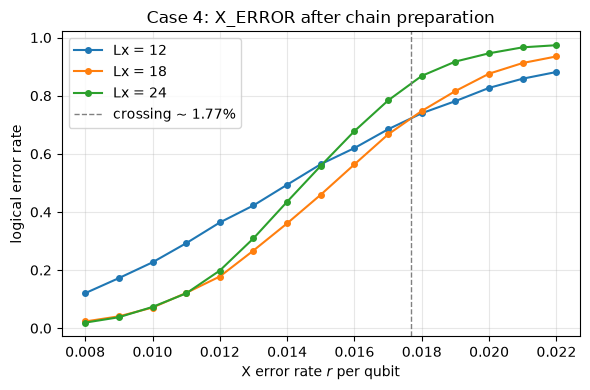

In [24]:
ps4 = np.linspace(0.008, 0.022, 15)
t0 = time.time()
cols4 = {}
for L, xm in zip(LS, X_MAXES):
    tl = time.time()
    cols4[L] = sweep_state_noise(xm, "X_ERROR", ps4, shots=SHOTS)
    print(f"  [Lx={L}: {len(ps4)} points in {time.time() - tl:.1f}s]", flush=True)
xc4 = report("Case 4: X errors on the prepared chains", ps4, cols4, LS, unit="r")
print(f"\ntotal {time.time() - t0:.1f}s")
plot_sweep(ps4, cols4, LS, "X error rate $r$ per qubit",
           "Case 4: X_ERROR after chain preparation",
           crossing=next((x for x in xc4 if x), None))

  [Lx=12: 15 points in 16.8s]


  [Lx=18: 15 points in 60.4s]


  [Lx=24: 15 points in 149.7s]



Case 5: Y errors on the prepared chains (X+Z decoder)
       r     Lx=12     Lx=18     Lx=24
  0.0030    0.0417    0.0141    0.0069
  0.0033    0.0636    0.0278    0.0137
  0.0036    0.0780    0.0475    0.0257
  0.0039    0.1029    0.0745    0.0449
  0.0041    0.1345    0.0957    0.0742
  0.0044    0.1614    0.1432    0.1129
  0.0047    0.1923    0.1875    0.1766
  0.0050    0.2372    0.2553    0.2494
  0.0053    0.2781    0.3088    0.3357
  0.0056    0.3181    0.3760    0.4320
  0.0059    0.3661    0.4403    0.5330
  0.0061    0.3956    0.5152    0.6233
  0.0064    0.4519    0.5890    0.7104
  0.0067    0.4944    0.6551    0.7788
  0.0070    0.5261    0.7045    0.8449

  pairwise crossings:
    Lx=12 x Lx=18: r_th ~= 0.0048  (0.48%)
    Lx=18 x Lx=24: r_th ~= 0.0051  (0.51%)

total 226.9s


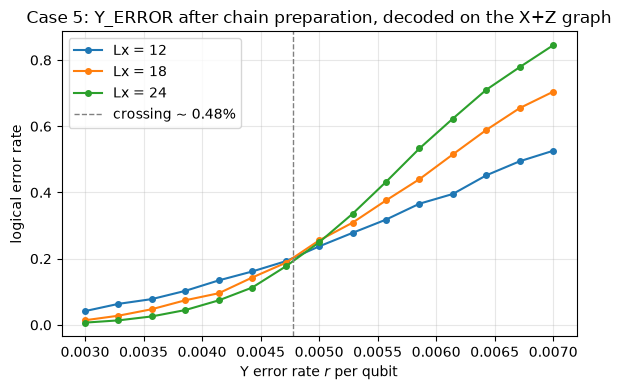

In [25]:
ps5 = np.linspace(0.003, 0.007, 15)
t0 = time.time()
cols5 = {}
for L, xm in zip(LS, X_MAXES):
    tl = time.time()
    cols5[L] = sweep_state_noise(xm, "Y_ERROR", ps5, shots=SHOTS,
                                 decoder_instructions=["X_ERROR", "Z_ERROR"])
    print(f"  [Lx={L}: {len(ps5)} points in {time.time() - tl:.1f}s]", flush=True)
xc5 = report("Case 5: Y errors on the prepared chains (X+Z decoder)", ps5, cols5, LS, unit="r")
print(f"\ntotal {time.time() - t0:.1f}s")
plot_sweep(ps5, cols5, LS, "Y error rate $r$ per qubit",
           "Case 5: Y_ERROR after chain preparation, decoded on the X+Z graph",
           crossing=next((x for x in xc5 if x), None))

### Summary

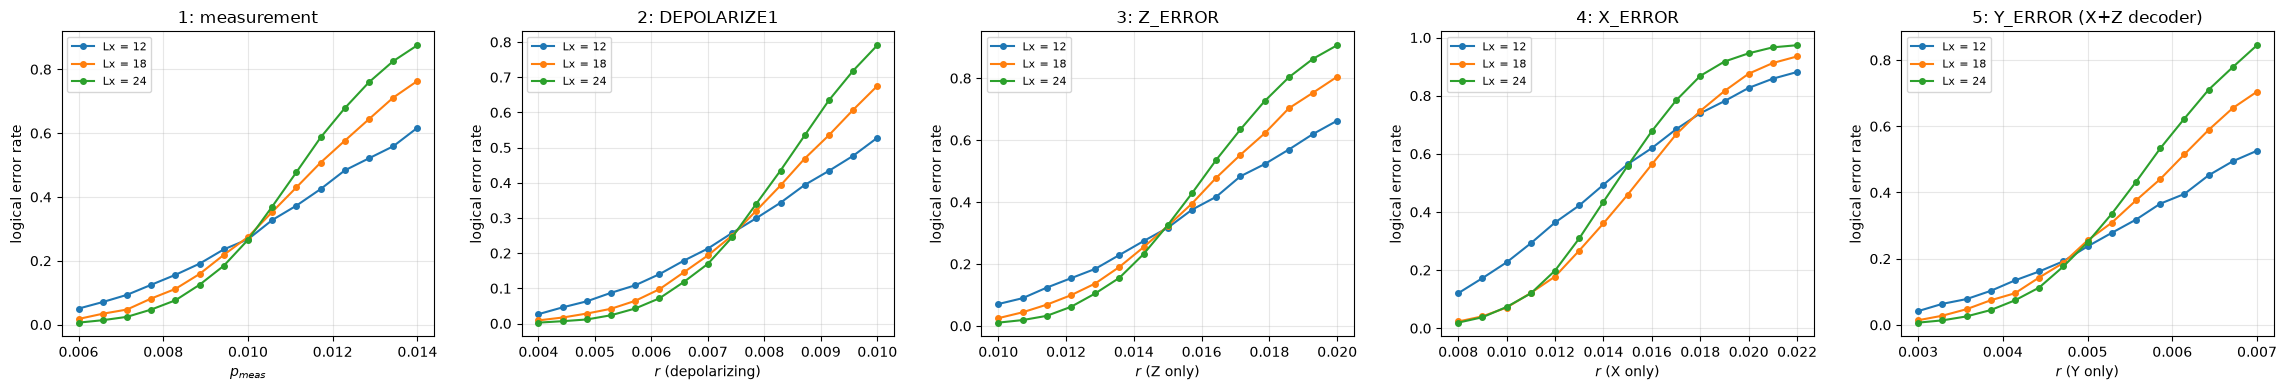

                        case    12 x 18    18 x 24
        1  measurement error       0.98%      1.02%
   2  depolarizing on chains       0.75%      0.75%
        3  Z error on chains       1.48%      1.49%
        4  X error on chains       1.77%      0.96%
        5  Y error on chains       0.48%      0.51%

10000 shots per point, 15 points per case, Lx = [12, 18, 24].
Case 5 is decoder-limited: a pure-Y model is not graphlike (see above).
Crossing interpolation only -- no finite-size-scaling fit, no error bars.


In [26]:
fig, axes = plt.subplots(1, 5, figsize=(23, 4))
for ax, (ps, cols, lab, ttl) in zip(axes, [
        (ps1, cols1, "$p_{meas}$", "1: measurement"),
        (ps2, cols2, "$r$ (depolarizing)", "2: DEPOLARIZE1"),
        (ps3, cols3, "$r$ (Z only)", "3: Z_ERROR"),
        (ps4, cols4, "$r$ (X only)", "4: X_ERROR"),
        (ps5, cols5, "$r$ (Y only)", "5: Y_ERROR (X+Z decoder)")]):
    for L in LS:
        ax.plot(ps, cols[L], "o-", ms=4, label=f"Lx = {L}")
    ax.set_xlabel(lab); ax.set_ylabel("logical error rate")
    ax.set_title(ttl); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{'case':>28} {'12 x 18':>10} {'18 x 24':>10}")
for name, xc in (("1  measurement error", xc1),
                 ("2  depolarizing on chains", xc2),
                 ("3  Z error on chains", xc3),
                 ("4  X error on chains", xc4),
                 ("5  Y error on chains", xc5)):
    cells = "".join(f"{(f'{v*100:.2f}%' if v else '--'):>11}" for v in xc)
    print(f"{name:>28} {cells}")
print(f"\n{SHOTS} shots per point, 15 points per case, Lx = {LS}.")
print("Case 5 is decoder-limited: a pure-Y model is not graphlike (see above).")
print("Crossing interpolation only -- no finite-size-scaling fit, no error bars.")

---
### Reading the numbers

- All three curves order correctly by distance below the crossing and invert
  above it, which is the qualitative signature a threshold should show.
- Case 1 reproduces the ~1% measurement threshold of
  `Hexagon_fbqc_walkthrough.ipynb` §6, as it must: §3 and §6 establish that this
  network *is* that code, so the same noise model has to give the same number.
  It is a useful end-to-end check on the whole construction.
- Case 3 sits higher than case 1 in `r` for a structural reason, not because the
  code is more robust to `Z`: only one of each fusion's two records can be
  flipped by this channel, so at a given rate it corrupts half as much of the
  syndrome.
- Case 2 sits lowest, as expected -- a depolarizing qubit is three Pauli
  channels at once, and both records of a fusion can be affected.
- The three single-qubit Pauli channels separate widely once they act on the
  *entangled* chains -- and collapse entirely if applied at state preparation,
  where `X` is invisible and `Y` and `Z` are the same channel. All five sweeps
  therefore share one splice point, after the CZ layer.
- Case 5's number is limited by the `X`+`Z` decoder, not only by the code. A
  decoder that keeps the `X`-`Z` correlation inside each `Y` (a correlated
  matcher, or belief propagation) would place it higher.
- Case 4 is the one not to quote as a single number. Cases 1, 2, 3 and 5 give
  two pairwise crossings that agree to within a few hundredths of a percent;
  case 4's disagree by nearly a factor of two, because `Lx = 18` and `Lx = 24`
  are nearly degenerate against `X` noise. Finding out why -- most likely a
  low-weight `X`-type logical whose weight saturates with `Lx` -- is the obvious
  next thing to look at, and is exactly the kind of question §6's closed forms
  are set up to answer.

These are crossing estimates at 10,000 shots. For publication numbers, redo them
with a finite-size-scaling fit and more shots, as the erasure and measurement
sections of `Hexagon_fbqc_walkthrough.ipynb` do.